# Етап 7 — Перевірка стійкості до adversarial-атак (FGSM, PGD)

За планом (п.53–55): застосувати прості adversarial-атаки (FGSM, PGD) до
мережевої моделі через бібліотеку ART, і перевірити, чи гібридна модель
(з поведінковим сигналом) стійкіша до таких атак, ніж чисто мережева —
тобто чи компенсує другий канал (поведінка) обман першого (мережа).

## Технічне уточнення
FGSM і PGD — це градієнтні («білоскринькові») атаки: їм потрібна модель,
через яку можна порахувати похідну. RandomForest/XGBoost із 03 для цього
не підходять напряму (дерева недиференційовні). Тому тут окремо
навчається невелика диференційовна модель — проста нейромережа (MLP) —
спеціально для цього експерименту; RF/XGBoost із 03 залишаються основними
моделями роботи, тут вони не замінюються.

## Те саме методологічне обмеження, що й у 06/06а
Поведінкові й мережеві дані — незалежні датасети без спільних прикладів.
Тому, за прикладом 06а (domain shift), тут так само СИМУЛЮЄМО пари
(score_behavioral, score_network), додатково з явним припущенням:
атакувальник, що спотворює МЕРЕЖЕВИЙ трафік (adversarial-приклад), не
може одночасно й узгоджено підробити статистику РУХУ МИШІ жертви —
тобто поведінковий канал під час мережевої atacи лишається «чистим».
Це припущення явно позначене й обговорюється в підсумку.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

!pip install -q adversarial-robustness-toolbox joblib

import os
import glob
import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Input
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score

from art.estimators.classification import TensorFlowV2Classifier
from art.attacks.evasion import FastGradientMethod, ProjectedGradientDescent

PROJECT_DIR = '/content/drive/MyDrive/man-bot-detection'
DATA_BASE = os.path.join(PROJECT_DIR, 'data/raw')
OUTPUT_DIR = os.path.join(PROJECT_DIR, 'notebooks/results')
os.makedirs(os.path.join(OUTPUT_DIR, 'figures'), exist_ok=True)
os.makedirs(os.path.join(OUTPUT_DIR, 'tables'), exist_ok=True)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
tf.random.set_seed(RANDOM_STATE)

Mounted at /content/drive
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.1/1.1 MB 16.6 MB/s eta 0:00:00


## Частина A. Навчання диференційовної мережевої моделі (MLP) на CIC-IDS2017

In [2]:
cic_files = glob.glob(os.path.join(DATA_BASE, 'cic_ids_2017', '*.csv'))
df_cic = pd.concat([pd.read_csv(f, low_memory=False) for f in cic_files], ignore_index=True)
if len(df_cic) > 200000:
    df_cic = df_cic.sample(n=200000, random_state=RANDOM_STATE)
df_cic = df_cic.replace([np.inf, -np.inf], np.nan).dropna()

y_net = (df_cic[' Label'].astype(str).str.strip() != 'BENIGN').astype(int).values
X_net = df_cic.drop(columns=[' Label']).select_dtypes(include=[np.number])
feature_names_net = list(X_net.columns)
print(f"CIC-IDS2017: {X_net.shape[0]} рядків, {X_net.shape[1]} ознак, "
      f"класи 0={sum(y_net==0)}, 1={sum(y_net==1)}")

X_net_train, X_net_test, y_net_train, y_net_test = train_test_split(
    X_net.values, y_net, test_size=0.2, random_state=RANDOM_STATE, stratify=y_net
)

scaler_net = StandardScaler()
X_net_train_s = scaler_net.fit_transform(X_net_train).astype(np.float32)
X_net_test_s = scaler_net.transform(X_net_test).astype(np.float32)

n_features = X_net_train_s.shape[1]

mlp = Sequential([
    Input(shape=(n_features,)),
    Dense(64, activation='relu'),
    Dropout(0.2),
    Dense(32, activation='relu'),
    Dense(2, activation='softmax'),                                                        
])
mlp.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
mlp.fit(X_net_train_s, y_net_train, epochs=15, batch_size=256, validation_split=0.1, verbose=1)

clean_pred = mlp.predict(X_net_test_s, verbose=0).argmax(axis=1)
clean_acc = accuracy_score(y_net_test, clean_pred)
clean_f1 = f1_score(y_net_test, clean_pred, zero_division=0)
print(f"\n✅ MLP (чисті дані, без атаки): Accuracy={clean_acc:.4f}, F1={clean_f1:.4f}")

CIC-IDS2017: 199747 рядків, 78 ознак, класи 0=131021, 1=68726
Epoch 1/15
562/562 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.9537 - loss: 0.1204 - val_accuracy: 0.9796 - val_loss: 0.0627
Epoch 2/15
562/562 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9777 - loss: 0.0613 - val_accuracy: 0.9799 - val_loss: 0.0504
Epoch 3/15
562/562 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9814 - loss: 0.0503 - val_accuracy: 0.9835 - val_loss: 0.0453
Epoch 4/15
562/562 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9836 - loss: 0.0450 - val_accuracy: 0.9859 - val_loss: 0.0414
Epoch 5/15
562/562 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9849 - loss: 0.0414 - val_accuracy: 0.9879 - val_loss: 0.0398
Epoch 6/15
562/562 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9859 - loss: 0.0392 - val_accuracy: 0.9872 - val_loss: 0.0377
Epoch 7/15
562/562 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9862 - loss: 0.0367 - val_accuracy: 0.9866 - val_loss: 0.0347
Epoch 8/15
562/562 ━━━━━━━━━━━━━━━━━━━━ 4s

## Частина B. FGSM / PGD-атаки на мережеву модель (п.53–54 плану)

In [3]:
loss_object = tf.keras.losses.SparseCategoricalCrossentropy()
art_classifier = TensorFlowV2Classifier(
    model=mlp, nb_classes=2, input_shape=(n_features,),
    loss_object=loss_object, clip_values=(X_net_train_s.min(), X_net_train_s.max())
)

EPSILONS = [0.01, 0.05, 0.1, 0.2, 0.3, 0.5]

                                                                             
N_ATTACK_SAMPLES = 3000
rng = np.random.default_rng(RANDOM_STATE)
attack_idx = rng.choice(len(X_net_test_s), size=min(N_ATTACK_SAMPLES, len(X_net_test_s)), replace=False)
X_attack_base = X_net_test_s[attack_idx]
y_attack_base = y_net_test[attack_idx]

robustness_rows = []
adv_proba_by_eps = {}                                                      

                                      
proba_clean = mlp.predict(X_attack_base, verbose=0)[:, 1]
robustness_rows.append({
    'attack': 'none', 'epsilon': 0.0,
    'accuracy': accuracy_score(y_attack_base, (proba_clean >= 0.5).astype(int)),
    'f1': f1_score(y_attack_base, (proba_clean >= 0.5).astype(int), zero_division=0),
})
adv_proba_by_eps[('FGSM', 0.0)] = proba_clean
adv_proba_by_eps[('PGD', 0.0)] = proba_clean

for eps in EPSILONS:
    for attack_name, attack_obj in [
        ('FGSM', FastGradientMethod(estimator=art_classifier, eps=eps)),
        ('PGD', ProjectedGradientDescent(estimator=art_classifier, eps=eps,
                                          eps_step=eps / 4, max_iter=10, verbose=False)),
    ]:
        X_adv = attack_obj.generate(x=X_attack_base)
        proba_adv = mlp.predict(X_adv, verbose=0)[:, 1]
        y_pred_adv = (proba_adv >= 0.5).astype(int)
        acc = accuracy_score(y_attack_base, y_pred_adv)
        f1 = f1_score(y_attack_base, y_pred_adv, zero_division=0)
        robustness_rows.append({'attack': attack_name, 'epsilon': eps, 'accuracy': acc, 'f1': f1})
        adv_proba_by_eps[(attack_name, eps)] = proba_adv
        print(f"{attack_name:5s} eps={eps:.2f}:  Acc={acc:.4f}  F1={f1:.4f}")

df_robust = pd.DataFrame(robustness_rows)
df_robust.to_csv(os.path.join(OUTPUT_DIR, 'tables', 'adversarial_robustness_network_only.csv'), index=False)

FGSM  eps=0.01:  Acc=0.9497  F1=0.9277
PGD   eps=0.01:  Acc=0.9437  F1=0.9185
FGSM  eps=0.05:  Acc=0.8137  F1=0.7141
PGD   eps=0.05:  Acc=0.7903  F1=0.6866
FGSM  eps=0.10:  Acc=0.6983  F1=0.5540
PGD   eps=0.10:  Acc=0.5270  F1=0.4367
FGSM  eps=0.20:  Acc=0.2700  F1=0.2179
PGD   eps=0.20:  Acc=0.2033  F1=0.1764
FGSM  eps=0.30:  Acc=0.1303  F1=0.0605
PGD   eps=0.30:  Acc=0.0660  F1=0.0502
FGSM  eps=0.50:  Acc=0.0410  F1=0.0055
PGD   eps=0.50:  Acc=0.0133  F1=0.0047


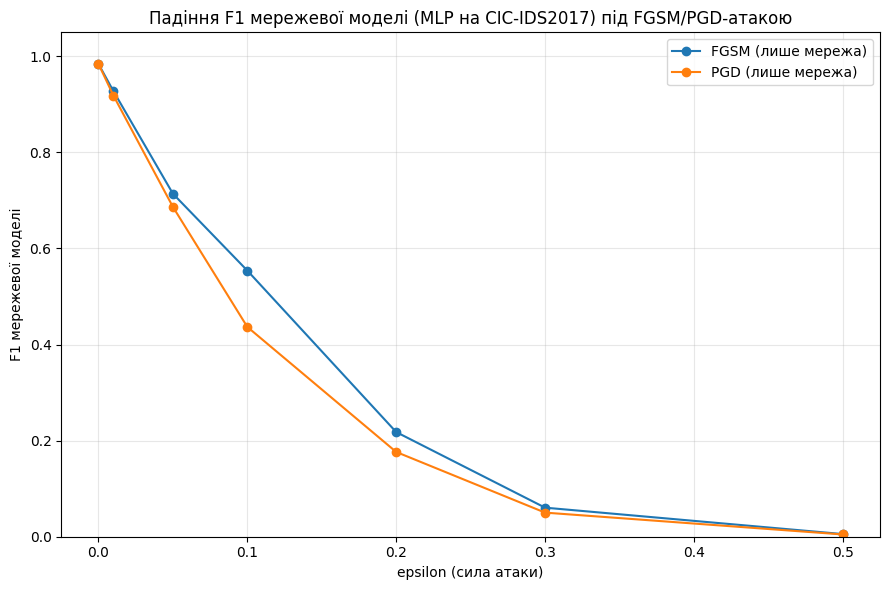

In [4]:
plt.figure(figsize=(9, 6))
for attack_name in ['FGSM', 'PGD']:
    sub = df_robust[(df_robust['attack'] == attack_name) | (df_robust['attack'] == 'none')]
    sub = sub.sort_values('epsilon')
    plt.plot(sub['epsilon'], sub['f1'], marker='o', label=f'{attack_name} (лише мережа)')
plt.xlabel('epsilon (сила атаки)')
plt.ylabel('F1 мережевої моделі')
plt.title('Падіння F1 мережевої моделі (MLP на CIC-IDS2017) під FGSM/PGD-атакою')
plt.ylim(0, 1.05)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, 'figures', 'adversarial_network_only_f1.png'), dpi=300)
plt.show()

## Частина C. Поведінковий сигнал (той самий, що й у 06/06а)

In [5]:
FEATURE_COLS_BEHAV = ['mean_speed', 'max_speed', 'std_speed', 'path_length',
                       'num_stops', 'mean_angle', 'num_clicks', 'num_points']

behav_csv = f'{PROJECT_DIR}/data/processed/behavioral_features_windowed.csv'
df_behav = pd.read_csv(behav_csv)
X_behav = df_behav[FEATURE_COLS_BEHAV]
y_behav = df_behav['label']

X_behav_train, X_behav_test, y_behav_train, y_behav_test = train_test_split(
    X_behav, y_behav, test_size=0.2, stratify=y_behav, random_state=RANDOM_STATE
)

rf_behav = joblib.load(f'{PROJECT_DIR}/models/behavioral_rf_300.pkl')
proba_behav_test = rf_behav.predict_proba(X_behav_test)[:, list(rf_behav.classes_).index('bot')]

behav_scores_by_class = {
    1: proba_behav_test[(y_behav_test == 'bot').values],                      
    0: proba_behav_test[(y_behav_test == 'human').values],                       
}
print(f"Поведінковий сигнал: {len(X_behav_test)} тестових вікон "
      f"(bot={sum(y_behav_test=='bot')}, human={sum(y_behav_test=='human')})")

Поведінковий сигнал: 7845 тестових вікон (bot=633, human=7212)


## Частина D. Симуляція fusion під зростаючою силою атаки (п.55 плану)

Для кожного epsilon будуємо симульовані пари (score_behavioral,
score_network_under_attack) — поведінковий сигнал ЗАВЖДИ чистий (він не
зазнає мережевої adversarial-атаки, див. припущення на початку ноутбука),
мережевий сигнал — під конкретною силою атаки. Порівнюємо: чи гібридна
(мета-)модель тримає F1 краще, ніж чисто мережева, зі зростанням epsilon.

In [6]:
N_SIM_PER_CLASS = 3000
rng = np.random.default_rng(RANDOM_STATE)


def simulate_pairs(net_proba_by_class, n_per_class=N_SIM_PER_CLASS):
    rows = []
    for cls in [0, 1]:
        behav_pool = behav_scores_by_class[cls]
        net_pool = net_proba_by_class[cls]
        sb = rng.choice(behav_pool, size=n_per_class, replace=True)
        sn = rng.choice(net_pool, size=n_per_class, replace=True)
        for a, b in zip(sb, sn):
            rows.append({'score_behavioral': a, 'score_network': b, 'is_attack': cls})
    return pd.DataFrame(rows)


                                                                            
                                                                    
                                                 
net_proba_clean_by_class = {
    1: adv_proba_by_eps[('FGSM', 0.0)][y_attack_base == 1],
    0: adv_proba_by_eps[('FGSM', 0.0)][y_attack_base == 0],
}
df_sim_clean = simulate_pairs(net_proba_clean_by_class)
X_meta_train = df_sim_clean[['score_behavioral', 'score_network']]
y_meta_train = df_sim_clean['is_attack']
meta_model = LogisticRegression(random_state=RANDOM_STATE)
meta_model.fit(X_meta_train, y_meta_train)
print(f"Мета-модель навчена на {len(df_sim_clean)} чистих симульованих парах.")
print(f"Ваги: behavioral={meta_model.coef_[0][0]:.3f}, network={meta_model.coef_[0][1]:.3f}")

Мета-модель навчена на 6000 чистих симульованих парах.
Ваги: behavioral=6.281, network=7.809


In [7]:
comparison_rows = []
for attack_name in ['FGSM', 'PGD']:
    for eps in [0.0] + EPSILONS:
        proba_adv = adv_proba_by_eps[(attack_name, eps)]
        net_proba_by_class = {
            1: proba_adv[y_attack_base == 1],
            0: proba_adv[y_attack_base == 0],
        }
        df_sim_eval = simulate_pairs(net_proba_by_class, n_per_class=2000)

                                      
        y_pred_net_only = (df_sim_eval['score_network'] >= 0.5).astype(int)
        f1_net_only = f1_score(df_sim_eval['is_attack'], y_pred_net_only, zero_division=0)

                                                                       
        y_pred_hybrid = meta_model.predict(df_sim_eval[['score_behavioral', 'score_network']])
        f1_hybrid = f1_score(df_sim_eval['is_attack'], y_pred_hybrid, zero_division=0)

        comparison_rows.append({'attack': attack_name, 'epsilon': eps,
                                 'f1_network_only': f1_net_only, 'f1_hybrid': f1_hybrid,
                                 'improvement': f1_hybrid - f1_net_only})

df_comparison = pd.DataFrame(comparison_rows)
print(df_comparison.to_string(index=False))
df_comparison.to_csv(os.path.join(OUTPUT_DIR, 'tables', 'adversarial_hybrid_vs_network.csv'), index=False)

attack  epsilon  f1_network_only  f1_hybrid  improvement
  FGSM     0.00         0.989552   0.992791     0.003239
  FGSM     0.01         0.931748   0.966675     0.034927
  FGSM     0.05         0.739168   0.856452     0.117283
  FGSM     0.10         0.609339   0.771252     0.161913
  FGSM     0.20         0.285573   0.529539     0.243965
  FGSM     0.30         0.086934   0.428945     0.342011
  FGSM     0.50         0.009200   0.372220     0.363020
   PGD     0.00         0.991781   0.993536     0.001755
   PGD     0.01         0.927937   0.966440     0.038502
   PGD     0.05         0.718768   0.826660     0.107892
   PGD     0.10         0.514040   0.684785     0.170745
   PGD     0.20         0.240894   0.483776     0.242882
   PGD     0.30         0.068586   0.384075     0.315489
   PGD     0.50         0.003026   0.356579     0.353553


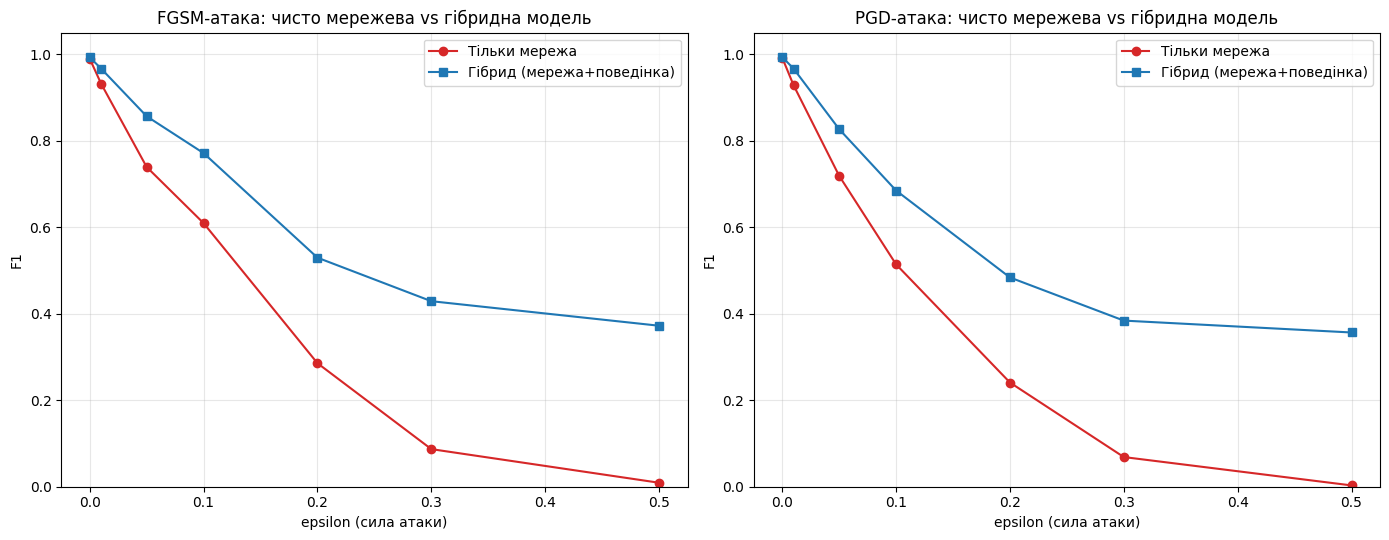

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for ax, attack_name in zip(axes, ['FGSM', 'PGD']):
    sub = df_comparison[df_comparison['attack'] == attack_name].sort_values('epsilon')
    ax.plot(sub['epsilon'], sub['f1_network_only'], marker='o', label='Тільки мережа', color='tab:red')
    ax.plot(sub['epsilon'], sub['f1_hybrid'], marker='s', label='Гібрид (мережа+поведінка)', color='tab:blue')
    ax.set_xlabel('epsilon (сила атаки)')
    ax.set_ylabel('F1')
    ax.set_title(f'{attack_name}-атака: чисто мережева vs гібридна модель')
    ax.set_ylim(0, 1.05)
    ax.grid(alpha=0.3)
    ax.legend()
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, 'figures', 'adversarial_hybrid_vs_network.png'), dpi=300)
plt.show()

## Частина E. Підсумок

In [9]:
print("="*70)
print("ПІДСУМОК ЕТАПУ 7 — СТІЙКІСТЬ ДО ADVERSARIAL-АТАК")
print("="*70)

for attack_name in ['FGSM', 'PGD']:
    sub = df_comparison[df_comparison['attack'] == attack_name].sort_values('epsilon')
    max_eps_row = sub.iloc[-1]
    mean_improvement = sub[sub['epsilon'] > 0]['improvement'].mean()
    print(f"\n{attack_name}:")
    print(f"  При найсильнішій атаці (epsilon={max_eps_row['epsilon']}): "
          f"F1 лише мережа = {max_eps_row['f1_network_only']:.4f}, "
          f"F1 гібрид = {max_eps_row['f1_hybrid']:.4f} "
          f"({max_eps_row['improvement']:+.4f})")
    print(f"  Середній приріст F1 від гібридизації по всіх epsilon>0: {mean_improvement:+.4f}")

print("""
⚠️ ОБМЕЖЕННЯ (як і в 06/06а):
1. Результат отримано на СИМУЛЬОВАНИХ парах (score_behavioral,
   score_network) під припущенням умовної незалежності модальностей —
   не на реальних парних даних одного й того самого сеансу атаки.
2. Додаткове припущення саме цього експерименту: атакувальник, що підбирає
   adversarial-приклад мережевого трафіку, не змінює одночасно поведінкові
   характеристики (рух миші) — цей канал вважається "чистим" під час
   мережевої атаки. Це поширене й обґрунтоване припущення в літературі з
   мультимодального захисту (два незалежні сенсори важче обманути
   одночасно), але воно НЕ доведено емпірично в межах цього дослідження.
3. FGSM/PGD застосовано до окремо навченої диференційовної моделі (MLP),
   а не до основних RandomForest/XGBoost моделей 03 — деревні ансамблі
   вимагають інших методів атаки (напр. ART DecisionTreeAttack,
   ZooAttack), що виходить за межі цього етапу.
""")

ПІДСУМОК ЕТАПУ 7 — СТІЙКІСТЬ ДО ADVERSARIAL-АТАК

FGSM:
  При найсильнішій атаці (epsilon=0.5): F1 лише мережа = 0.0092, F1 гібрид = 0.3722 (+0.3630)
  Середній приріст F1 від гібридизації по всіх epsilon>0: +0.2105

PGD:
  При найсильнішій атаці (epsilon=0.5): F1 лише мережа = 0.0030, F1 гібрид = 0.3566 (+0.3536)
  Середній приріст F1 від гібридизації по всіх epsilon>0: +0.2048

⚠️ ОБМЕЖЕННЯ (як і в 06/06а):
1. Результат отримано на СИМУЛЬОВАНИХ парах (score_behavioral,
   score_network) під припущенням умовної незалежності модальностей —
   не на реальних парних даних одного й того самого сеансу атаки.
2. Додаткове припущення саме цього експерименту: атакувальник, що підбирає
   adversarial-приклад мережевого трафіку, не змінює одночасно поведінкові
   характеристики (рух миші) — цей канал вважається "чистим" під час
   мережевої атаки. Це поширене й обґрунтоване припущення в літературі з
   мультимодального захисту (два незалежні сенсори важче обманути
   одночасно), але воно НЕ дов